In [1]:
# Task 2: NLP Sentiment Classifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import requests

# Download the training dataset
base_url = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/"

train_text = requests.get(base_url + "train_text.txt")
train_labels = requests.get(base_url + "train_labels.txt")

test_text = requests.get(base_url + "test_text.txt")
test_labels = requests.get(base_url + "test_labels.txt")

# Check downloads
assert train_text.status_code == 200
assert train_labels.status_code == 200
assert test_text.status_code == 200
assert test_labels.status_code == 200

# Create training and testing dataframes
train_df = pd.DataFrame({
    "text": train_text.text.splitlines(),
    "sentiment": train_labels.text.splitlines()
})

test_df = pd.DataFrame({
    "text": test_text.text.splitlines(),
    "sentiment": test_labels.text.splitlines()
})

# Convert labels into integers
train_df["sentiment"] = train_df["sentiment"].astype(int)
test_df["sentiment"] = test_df["sentiment"].astype(int)

print("Dataset downloaded successfully!")
print("\nTraining dataset:", len(train_df))
print("Testing dataset:", len(test_df))

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nSample data:")
display(train_df.head())

Dataset downloaded successfully!

Training dataset: 45615
Testing dataset: 12284

Sentiment distribution:
sentiment
1    20673
2    17849
0     7093
Name: count, dtype: int64

Sample data:


,text,sentiment
0,"""QT @user In the original draft of the 7th boo...",2
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1
3,Chase Headley's RBI double in the 8th inning o...,1
4,@user Alciato: Bee will invest 150 million in ...,2


In [3]:
print("Dataset verification")
print("---------------------")

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nSentiment categories:")
print(train_df["sentiment"].value_counts())

print("\nFirst 5 sample tweets:")
for i in range(5):
    print(i+1, train_df["text"].iloc[i])
    print("Sentiment:", train_df["sentiment"].iloc[i])
    print()

Dataset verification
---------------------
Training rows: 45615
Testing rows: 12284

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment categories:
sentiment
1    20673
2    17849
0     7093
Name: count, dtype: int64

First 5 sample tweets:
1 "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 
Sentiment: 2

2 "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ" 
Sentiment: 1

3 Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Minecraft in pc tomorrow night. 
Sentiment: 1

4 Chase Headley's RBI double in the 8th inning off David Price snapped a Yankees streak of 33 consecutive scoreless innings against Blue Jays 
Sentiment: 1

5 @user Alciato: Bee will invest 150 million in January, another 200 in the Summer and plans to bring Messi by 2017" 
Sentiment: 2



In [4]:
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLP resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Text cleaning function
def preprocess_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove mentions
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol
    text = text.replace('#', '')

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Tokenization
    words = text.split()

    # Stop-word removal and lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


# Apply preprocessing
train_df['clean_text'] = train_df['text'].apply(preprocess_text)
test_df['clean_text'] = test_df['text'].apply(preprocess_text)

print("Text preprocessing completed!")

print("\nOriginal text:")
print(train_df['text'].iloc[0])

print("\nCleaned text:")
print(train_df['clean_text'].iloc[0])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Text preprocessing completed!

Original text:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 

Cleaned text:
qt original draft 7th book remus lupin survived battle hogwarts happybirthdayremuslupin


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

# Transform training and testing text
X_train = tfidf.fit_transform(train_df['clean_text'])
X_test = tfidf.transform(test_df['clean_text'])

# Target labels
y_train = train_df['sentiment']
y_test = test_df['sentiment']

print("TF-IDF vectorization completed!")

print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF vectorization completed!
Training matrix shape: (45615, 5000)
Testing matrix shape: (12284, 5000)
Number of features: 5000


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize the model
model = LogisticRegression(max_iter=1000)

# Train the model
print("Training model...")

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("\nModel training completed successfully!")

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training model...

Model training completed successfully!

Model Accuracy: 58.08 %

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.38      0.48      3972
           1       0.59      0.72      0.65      5937
           2       0.50      0.55      0.53      2375

    accuracy                           0.58     12284
   macro avg       0.58      0.55      0.55     12284
weighted avg       0.59      0.58      0.57     12284



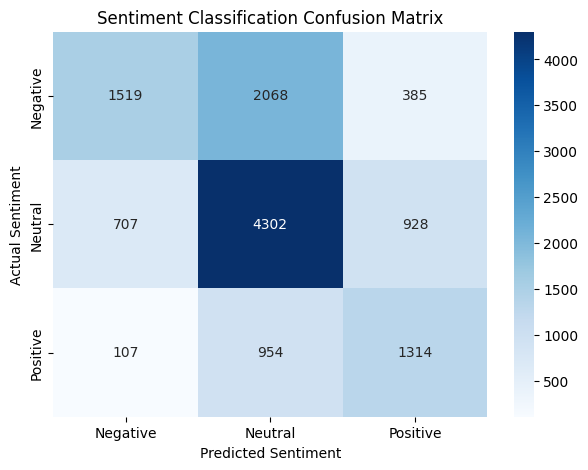

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Sentiment Classification Confusion Matrix')

plt.show()

In [8]:
# Test our sentiment classifier with new sentences

test_sentences = [
    "I absolutely love this product, it is amazing!",
    "This is the worst experience I have ever had.",
    "The meeting is scheduled for tomorrow.",
    "I am extremely happy with my results.",
    "The service was disappointing and terrible."
]

# Preprocess sentences
cleaned_sentences = [
    preprocess_text(sentence) for sentence in test_sentences
]

# Convert sentences using trained TF-IDF
sentence_vectors = tfidf.transform(cleaned_sentences)

# Predict sentiments
predictions = model.predict(sentence_vectors)

# Sentiment labels
sentiment_labels = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# Display predictions
print("CUSTOM SENTIMENT PREDICTIONS")
print("----------------------------")

for sentence, prediction in zip(test_sentences, predictions):
    print("\nSentence:", sentence)
    print("Predicted Sentiment:", sentiment_labels[prediction])

CUSTOM SENTIMENT PREDICTIONS
----------------------------

Sentence: I absolutely love this product, it is amazing!
Predicted Sentiment: Positive

Sentence: This is the worst experience I have ever had.
Predicted Sentiment: Negative

Sentence: The meeting is scheduled for tomorrow.
Predicted Sentiment: Neutral

Sentence: I am extremely happy with my results.
Predicted Sentiment: Positive

Sentence: The service was disappointing and terrible.
Predicted Sentiment: Negative


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Improved TF-IDF vectorization
tfidf_improved = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Transform text data
X_train_improved = tfidf_improved.fit_transform(train_df['clean_text'])
X_test_improved = tfidf_improved.transform(test_df['clean_text'])

# Initialize LinearSVC
svm_model = LinearSVC(C=1.0)

# Train model
svm_model.fit(X_train_improved, y_train)

# Predictions
svm_predictions = svm_model.predict(X_test_improved)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Improved Model Training Completed!")
print("Previous Accuracy:", round(accuracy * 100, 2), "%")
print("New Model Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

Improved Model Training Completed!
Previous Accuracy: 58.08 %
New Model Accuracy: 57.2 %

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.48      0.54      3972
           1       0.61      0.61      0.61      5937
           2       0.47      0.62      0.53      2375

    accuracy                           0.57     12284
   macro avg       0.56      0.57      0.56     12284
weighted avg       0.58      0.57      0.57     12284



In [10]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize Naive Bayes
nb_model = MultinomialNB(alpha=0.1)

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Model Results")
print("-------------------------")

print("Logistic Regression:",
      round(accuracy * 100, 2), "%")

print("LinearSVC:",
      round(svm_accuracy * 100, 2), "%")

print("Naive Bayes:",
      round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Model Results
-------------------------
Logistic Regression: 58.08 %
LinearSVC: 57.2 %
Naive Bayes: 56.24 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.30      0.42      3972
           1       0.57      0.74      0.64      5937
           2       0.48      0.55      0.51      2375

    accuracy                           0.56     12284
   macro avg       0.57      0.53      0.52     12284
weighted avg       0.58      0.56      0.54     12284



In [11]:
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Preserve important negative words
stop_words = set(stopwords.words('english'))

negation_words = {'no', 'not', 'nor', 'never'}

stop_words = stop_words - negation_words

lemmatizer = WordNetLemmatizer()

# Improved preprocessing function
def improved_preprocess(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove usernames
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol
    text = text.replace('#', '')

    # Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    words = text.split()

    # Remove stop words but preserve negations
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


# Apply improved preprocessing
train_df['improved_text'] = train_df['text'].apply(
    improved_preprocess
)

test_df['improved_text'] = test_df['text'].apply(
    improved_preprocess
)

print("Improved preprocessing completed!")

print("\nOriginal:")
print(train_df['text'].iloc[0])

print("\nPrevious cleaning:")
print(train_df['clean_text'].iloc[0])

print("\nImproved cleaning:")
print(train_df['improved_text'].iloc[0])

Improved preprocessing completed!

Original:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin" 

Previous cleaning:
qt original draft 7th book remus lupin survived battle hogwarts happybirthdayremuslupin

Improved cleaning:
qt original draft 7th book remus lupin survived battle hogwarts happybirthdayremuslupin


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create improved TF-IDF features
tfidf_new = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Transform improved text
X_train_new = tfidf_new.fit_transform(train_df['improved_text'])
X_test_new = tfidf_new.transform(test_df['improved_text'])

# Train Logistic Regression
improved_model = LogisticRegression(max_iter=1000)

improved_model.fit(X_train_new, y_train)

# Predict sentiments
improved_predictions = improved_model.predict(X_test_new)

# Calculate accuracy
improved_accuracy = accuracy_score(
    y_test, improved_predictions
)

print("IMPROVED MODEL RESULTS")
print("----------------------")

print("Original Accuracy:", round(accuracy * 100, 2), "%")

print("Improved Accuracy:",
      round(improved_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, improved_predictions))

IMPROVED MODEL RESULTS
----------------------
Original Accuracy: 58.08 %
Improved Accuracy: 59.52 %

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.40      0.51      3972
           1       0.60      0.73      0.66      5937
           2       0.51      0.58      0.54      2375

    accuracy                           0.60     12284
   macro avg       0.60      0.57      0.57     12284
weighted avg       0.61      0.60      0.59     12284



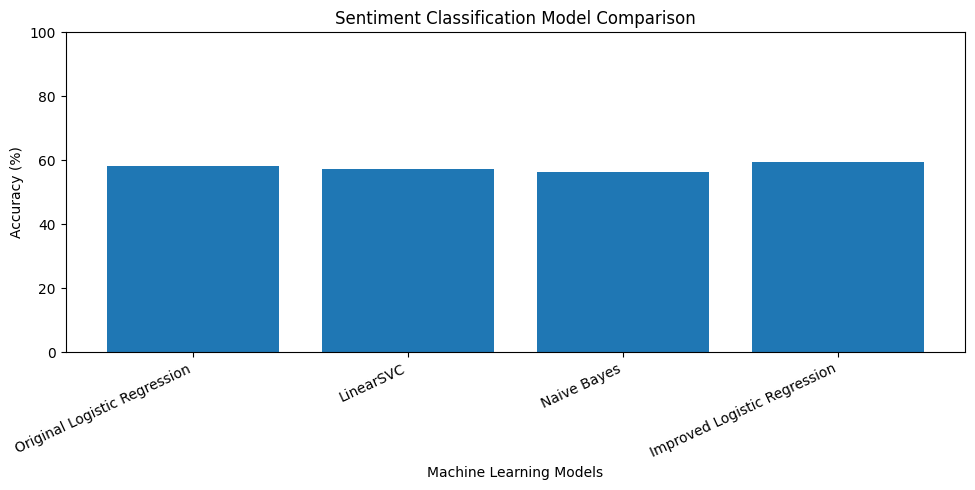

In [13]:
import matplotlib.pyplot as plt

models = [
    'Original Logistic Regression',
    'LinearSVC',
    'Naive Bayes',
    'Improved Logistic Regression'
]

accuracies = [
    accuracy * 100,
    svm_accuracy * 100,
    nb_accuracy * 100,
    improved_accuracy * 100
]

plt.figure(figsize=(10, 5))
plt.bar(models, accuracies)
plt.ylabel('Accuracy (%)')
plt.xlabel('Machine Learning Models')
plt.title('Sentiment Classification Model Comparison')
plt.ylim(0, 100)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [14]:
results = pd.DataFrame({
    'Model': [
        'Original Logistic Regression',
        'LinearSVC',
        'Naive Bayes',
        'Improved Logistic Regression'
    ],
    'Accuracy (%)': [
        round(accuracy * 100, 2),
        round(svm_accuracy * 100, 2),
        round(nb_accuracy * 100, 2),
        round(improved_accuracy * 100, 2)
    ]
})

display(results)

,Model,Accuracy (%)
0,Original Logistic Regression,58.08
1,LinearSVC,57.20
2,Naive Bayes,56.24
3,Improved Logistic Regression,59.52


In [15]:
print("""
PROJECT CONCLUSION
------------------

This project developed a multi-class sentiment
classification system using the TweetEval dataset.

The dataset contains three sentiment categories:
Negative, Neutral, and Positive.

Text preprocessing was performed using cleaning,
stopword removal, and lemmatization.

TF-IDF was used to convert text into numerical
features.

Four machine learning models were evaluated:
1. Logistic Regression
2. LinearSVC
3. Multinomial Naive Bayes
4. Improved Logistic Regression

The improved Logistic Regression model achieved
the highest accuracy of 59.52%.

The system can classify custom text into negative,
neutral, or positive sentiment categories.

This project demonstrates how Natural Language
Processing and machine learning can be used
for automated sentiment analysis.
""")


PROJECT CONCLUSION
------------------

This project developed a multi-class sentiment
classification system using the TweetEval dataset.

The dataset contains three sentiment categories:
Negative, Neutral, and Positive.

Text preprocessing was performed using cleaning,
stopword removal, and lemmatization.

TF-IDF was used to convert text into numerical
features.

Four machine learning models were evaluated:
1. Logistic Regression
2. LinearSVC
3. Multinomial Naive Bayes
4. Improved Logistic Regression

The improved Logistic Regression model achieved
the highest accuracy of 59.52%.

The system can classify custom text into negative,
neutral, or positive sentiment categories.

This project demonstrates how Natural Language
Processing and machine learning can be used
for automated sentiment analysis.

